# Распределения случайных величин

**Темы:** законы распределения дискретных и непрерывных СВ, свойства нормального распределения

**Идея ноутбука:** проверить теорию на практике. Генерируем много случайных значений, считаем их характеристики и сравниваем с формулами из курса. Если теория верна, числа должны почти совпасть.


## Подготовка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)   # чтобы при каждом запуске получались одни и те же числа
N = 10_000     # размер выборки: сколько значений генерируем

---
## 1. Биномиальное распределение

Это закон распределения вероятностей числа успешных исходов из n независимых испытаний, в каждом есть только либо успех, либо неудача.


**Формулы:** $M(X) = np$, $\quad D(X) = np(1-p)$, $\quad P(X=k) = C_n^k \, p^k (1-p)^{n-k}$

### 1.1 Генерация и сравнение с теорией

Параметры: $n = 10$ испытаний, вероятность успеха $p = 0.3$.

Сгенерируем `N` значений биномиальной СВ, посчитаем выборочное среднее и дисперсию и сравним их с теоретическими $M(X)$ и $D(X)$.

In [2]:
n = 10
p = 0.3
x=np.random.binomial(n, p, N) # 10000 серий по 10 испытаний


In [3]:
print(f"Выборочное среднее: {x.mean():.3f}")
print(f"M(X) теоретическое: {n*p:.3f}")
print(f"Выборочная дисперсия: {x.var():.3f}")
print(f"D(X) теоретическое: {n*p*(1-p):.3f}")

Выборочное среднее: 2.972
M(X) теоретическое: 3.000
Выборочная дисперсия: 2.054
D(X) теоретическое: 2.100


### 1.2 График частот

Построим столбчатую диаграмму: по оси X значения $k = 0, 1, …, 10$, по оси Y доля выборки, где выпало $k$. Поверх неё точками нанесём теоретические вероятности $P(X=k)$.

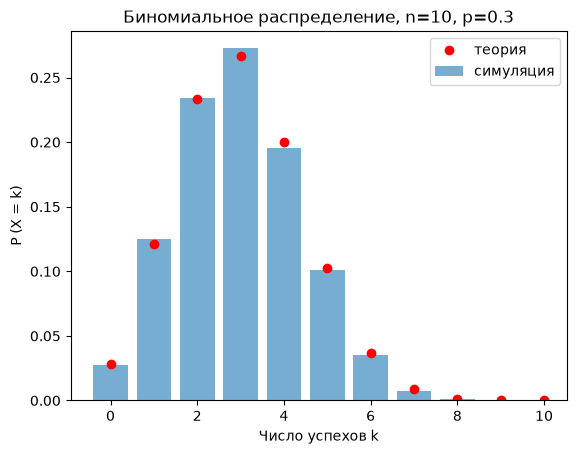

In [4]:
values, counts = np.unique(x, return_counts=True)
plt.bar(values, counts / N, label="симуляция", alpha=0.6)
k = np.arange(0,n+1)
p_theory = stats.binom.pmf(k, n, p)
plt.plot(k, p_theory, "o", color="red", label="теория")
plt.xlabel("Число успехов k")
plt.ylabel("P (X = k)")
plt.title(f"Биномиальное распределение, n={n}, p={p}")
plt.legend()
plt.show()




### 1.3 Вероятность события

Найдём $P(X \geq 5)$ двумя способами:
- **по симуляции:** доля значений выборки, которые ≥ 5;
- **по теории:** через `stats.binom`.

In [5]:
print(f"P(X ≥ 5) по симуляции: {(x>=5).mean():.3f}")
print(f"P(X ≥ 5) по формуле: {1-(stats.binom.cdf(4, n, p)):.3f}")

P(X ≥ 5) по симуляции: 0.145
P(X ≥ 5) по формуле: 0.150


---
## 2. Непрерывные распределения

Непрерывное распределение может принимать любые значения из какого-то интервала. Между любыми двумя значениями лежит бесконечное количество других. Для непрерывной величины вероятность попасть в интервал равна площади под графиком плотности на этом интервале. Одна точка — это интервал нулевой ширины, площадь над ним равна нулю, поэтому $P(X = a) = 0$, следовательно для непрерывных величин имеет смысл говорить только о вероятности попасть в интервал.

### 2.1 Равномерное распределение на $[a, b]$

**Формулы:** $M(X) = \frac{a+b}{2}$, $\quad D(X) = \frac{(b-a)^2}{12}$

Для $a = 2$, $b = 8$ сгенерируем `N` значений, сравним среднее и дисперсию с теорией и построим гистограмму.

In [6]:
a, b = 2, 8
u = np.random.uniform(a,b,N)

In [7]:
print(f"Среднее по теории: {(a+b)/2:.3f}")
print(f"Дисперсия по теории: {(b-a)**2/12:.3f}")
print(f"Среднее по симуляции: {u.mean():.3f}")
print(f"Дисперсия по симуляции: {u.var():.3f}")

Среднее по теории: 5.000
Дисперсия по теории: 3.000
Среднее по симуляции: 5.027
Дисперсия по симуляции: 3.013


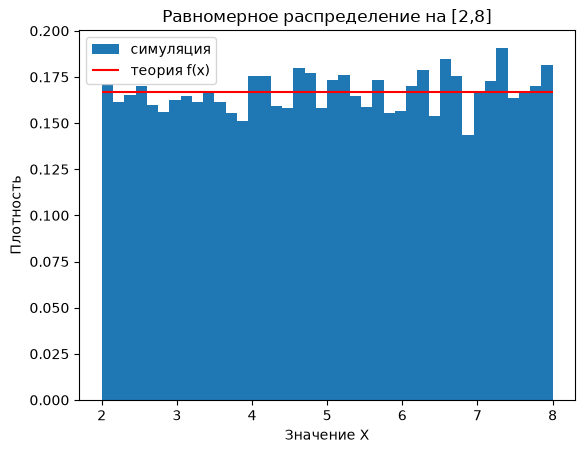

In [8]:
plt.hist(u, bins=40, density=True,  label="симуляция")
plt.hlines(1/(b-a), a, b, color="red", label="теория f(x)")
plt.xlabel("Значение X")
plt.ylabel("Плотность")
plt.title(f"Равномерное распределение на [{a},{b}]")
plt.legend()
plt.show()



Гистограмма имеет прямоугольную форму: все значения на отрезке равновероятны, поэтому в каждый интервал одинаковой ширины попадает примерно одинаковая доля чисел, и столбики получаются одной высоты. Эта высота должна быть около значения плотности $f(x) = \frac{1}{b-a} = \frac{1}{6} \approx 0.167$. Столбики колеблются около этой высоты, все получилось.

### 2.2 Показательное (экспоненциальное) распределение

**Формулы:** $f(x) = \lambda e^{-\lambda x}$, $\quad M(X) = \frac{1}{\lambda}$, $\quad D(X) = \frac{1}{\lambda^2}$

Для $\lambda = 0.5$:
1. сгенерируем `N` значений и сравним среднее и дисперсию с теорией;
2. построим гистограмму (`density=True`) и нанесём поверх неё теоретическую плотность $f(x)$;
3. найдём $P(X > 3)$ по симуляции и по формуле $e^{-3\lambda}$.

In [9]:
lam = 0.5
t = np.random.exponential(1/lam, N)

In [10]:
print(f"Среднее по теории: {(1/lam):.3f}")
print(f"Дисперсия по теории: {(1/(lam**2)):.3f}")
print(f"Среднее по симуляции: {t.mean():.3f}")
print(f"Дисперсия по симуляции: {t.var():.3f}")

Среднее по теории: 2.000
Дисперсия по теории: 4.000
Среднее по симуляции: 1.993
Дисперсия по симуляции: 3.962


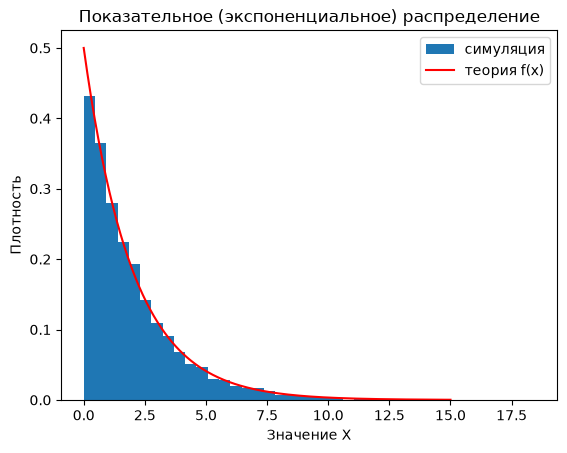

In [11]:
plt.hist(t, bins=40, density=True, label="симуляция")
xs = np.linspace(0, 15, 200)
plt.plot(xs, lam*np.exp(-lam*xs), color="red",label="теория f(x)")
plt.xlabel("Значение X")
plt.ylabel("Плотность")
plt.title("Показательное (экспоненциальное) распределение")
plt.legend()
plt.show()


In [12]:
print(f"P(X > 3) по симуляции: {(t>3).mean():.3f}") 
print(f"P(X > 3) по теории: {1-(stats.expon.cdf(3, scale=1/lam)):.3f}") # либо {1-(1-np.exp(-lam*3))}

P(X > 3) по симуляции: 0.220
P(X > 3) по теории: 0.223


---
## 3. Нормальное распределение

Если на какой-то процесс влияет множество различных мелких факторов, то суммарный результат будет стремиться именно к нормальному распределению. Большинство значений около среднего, а чем дальше от него, тем реже. График плотности - колокол. a - среднее, центр колокола. σ - среднее квадратическое отклонение, ширина колокола.

Пусть рост людей $X \sim N(a = 170, \ \sigma = 8)$.

### 3.1 Правило трёх сигм

Сгенерируем `N` значений роста. Для $k = 1, 2, 3$ посчитаем, какая доля значений попала в интервал $(a - k\sigma, \ a + k\sigma)$, и сравним с теорией: **68.27%**, **95.45%**, **99.73%**.

In [13]:
a = 170
sigma = 8
h = np.random.normal(a, sigma, N)
for k in range(1,4):
    lower = a - k*sigma
    higher = a + k*sigma
    share = ((h>lower)&(h<higher)).mean()
    share_theory = stats.norm.cdf(higher, a, sigma) - stats.norm.cdf(lower, a, sigma)
    print(f"±{k}σ ==> По симуляции {share*100:.1f}% | По теории {share_theory*100:.1f}%")



±1σ ==> По симуляции 68.2% | По теории 68.3%
±2σ ==> По симуляции 95.4% | По теории 95.4%
±3σ ==> По симуляции 99.7% | По теории 99.7%


### 3.2 Вероятность попадания в интервал

Найдём $P(160 < X < 185)$ тремя способами:
1. **по симуляции:** доля выборки в интервале;
2. **через `stats.norm.cdf`**;
3. **по формуле** через функцию Лапласа: $P(\alpha < X < \beta) = \Phi\left(\frac{\beta - a}{\sigma}\right) - \Phi\left(\frac{\alpha - a}{\sigma}\right)$.

In [14]:
lower1 = 160
higher1 = 185
share1 = ((h>lower1)&(h<higher1)).mean()
print(f"Способ по симуляции: P(160 < X < 185) = {share1:.3f}")

Способ по симуляции: P(160 < X < 185) = 0.863


In [15]:
share_theory1 = stats.norm.cdf(higher1, a, sigma)-stats.norm.cdf(lower1, a, sigma)
print(f"Через stats.norm.cdf: P(160 < X < 185) = {share_theory1:.3f}")

Через stats.norm.cdf: P(160 < X < 185) = 0.864


In [16]:
beta = 185
alpha = 160
two = (beta - a)/sigma
one = (alpha - a)/sigma
Phi_two = 0.4699
Phi_one = -0.3944
# по таблице: Φ(1.88) = 0.4699, Φ(1.25) = 0.3944
share_laplas = Phi_two - Phi_one
print(f"Через функцию Лапласа: P(160 < X < 185) = {share_laplas:.3f}")

Через функцию Лапласа: P(160 < X < 185) = 0.864


### 3.3 График

Построим гистограмму роста (`density=True`) и нанесём поверх неё теоретическую плотность нормального распределения. Вертикальными линиями отметим границы $a \pm \sigma$, $a \pm 2\sigma$, $a \pm 3\sigma$.

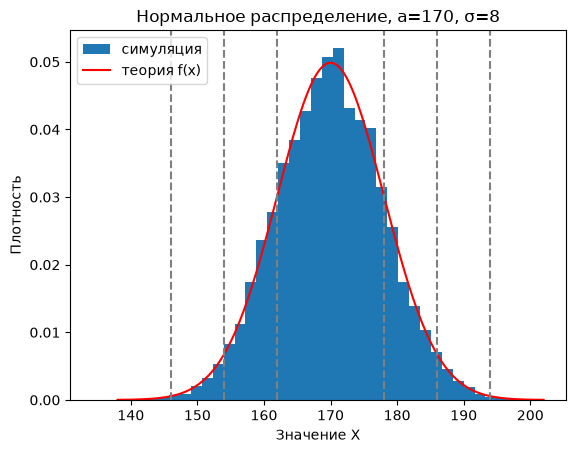

In [17]:
plt.hist(h, bins=40, density=True, label="симуляция")
xs1 = np.linspace(a - 4*sigma, a + 4*sigma, 200)
plt.plot(xs1, (1/(sigma*np.sqrt(2*np.pi)))*np.exp(-((xs1-a)**2)/(2*sigma**2)), color="red",label="теория f(x)") 
# можно было так: plt.plot(xs1, stats.norm.pdf(xs1, a, sigma), color="red", label="теория f(x)")
for k in range(1,4):
    lower = a - k*sigma
    higher = a + k*sigma
    plt.axvline(lower, color="gray", linestyle="--")
    plt.axvline(higher, color="gray", linestyle="--")
plt.xlabel("Значение X")
plt.ylabel("Плотность")
plt.legend()
plt.title(f"Нормальное распределение, a={a}, σ={sigma}")
plt.show()
    

---
## 4. Эксперимент: влияет ли размер выборки?
Поменял `N` на `100` и перезапустил ноутбук. Графики получаются неровные, рваные, соседние столбики сильно отличаются по высоте. Есть провалы, где-то пустые места. Форма распределения угадывается не так хорошо. Числа довольно сильно отличались от теории. Чем больше выборка, тем ближе к теории.

---
## 5. Выводы
Симуляция совпала с теорией для всех четырёх распределений: средние, дисперсии и вероятности отличаются от теоретических только в сотых.

Чем больше выборка, тем ближе симуляция к теории. При малой выборке (N = 100) расхождения заметные: в некоторые интервалы случайно не попадает ни одного значения, и на гистограмме появляются провалы, а в другие, наоборот, попадает много, и столбики получаются слишком высокими.

Есть распределения дискретные и непрерывные. Дискретные можно описать рядом распределения: у каждого значения своя вероятность $P(X = k)$, поэтому их можно сразу нарисовать столбиками (`plt.bar`). Непрерывные необходимо описывать с помощью плотности, потому что вероятность любого отдельного значения равна нулю, а вероятность попасть в интервал — это площадь под плотностью. Поэтому для них строится гистограмма с `density=True` и сравнивается с кривой $f(x)$.
